# Battery size optimization — continuous MILP sweep

Perfect-foresight cost of one household over a full year, solved once per battery capacity
from 0 to 100 kWh in the continuous formulation, so each point is the theoretical optimum
for that capacity.

The household has a PV self-supply device, so the price list is *Ponudnik 3 Samo
Dinamični* (`si_samooskrba`): import at SIPX + 0.01199 EUR/kWh plus
network charges, contributions and VAT, export credited at SIPX − 0.01199 EUR/kWh.

One MILP per capacity over the whole 35 136-step year, solved to a 0.1 % MIP gap. Every
solve starts and is required to end at half capacity, so a larger battery cannot book the
sell-off of its own opening charge as a saving.

In [1]:
### Imports
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pulp
from matplotlib import pyplot as plt
from matplotlib.ticker import FuncFormatter

import importlib
import Anonymous_Labels as anon
import Battery_Economics as be
import Data_Loader as dl
import Environment as environment_module
import MILP_Household as milp_module

anon = importlib.reload(anon)
dl = importlib.reload(dl)
environment_module = importlib.reload(environment_module)
milp_module = importlib.reload(milp_module)

HouseholdEnvironment = environment_module.HouseholdEnvironment
solve_household = milp_module.solve_household

print("Imports ready.")

Imports ready.


## 1. Configuration

In [2]:
### Household / dataset -----------------------------------------------------
# HOUSEHOLD_ID = "3-95546"
# DATASET_NAME = "PorabaDoma_3-95546_2025"   # real SI meter export, PV self-supply -> a samooskrba dynamic list
# SMP_COUNTRY_ID = "Slovenia"

HOUSEHOLD_ID = "123"
DATASET_NAME = "Fluvius"   # real SI meter export, PV self-supply -> a samooskrba dynamic list
SMP_COUNTRY_ID = "Slovenia"

PRICE_COLUMN = "SMP"
GENERATION_COLUMN = "Feed_In_Volume_kWh"
CONSUMPTION_COLUMN = "Consumption_Volume_kWh"

### Tariff ------------------------------------------------------------------
PRICING_SCHEME = "si_samooskrba"
# The catalogue KEY stays: it is what the pricing library is asked for, and it
# is what every cached row is filed under. Only the printed label is anonymous.
PAKET_ID = "GENI_SAMO_DINAMICNI"   # Ponudnik 3 Samo Dinamični; Samo Aktivni doseže boljše rezultate
PRICING_REFERENCE_YEAR = 2026      # dataset is 2025; SI tariff regime to price under
PEAK_RESET_MONTHS = 1           # repository default: ratchet peak never resets

### Battery -----------------------------------------------------------------
BATTERY_SIZES_KWH = np.unique(np.concatenate([
    np.arange(0.0, 11.0, 1.0),     # fine where the curve bends
    np.arange(12.5, 30.0, 2.5),
    np.arange(30.0, 101.0, 10.0),
]))

# Taken from MILP_Household rather than retyped, so every study in the
# repository sizes the same battery and solves it to the same gap.
CHARGE_EFFICIENCY = milp_module.CHARGE_EFFICIENCY
DISCHARGE_EFFICIENCY = milp_module.DISCHARGE_EFFICIENCY

# Power rating scales with capacity, capped at the inverter limit.
C_RATE = milp_module.C_RATE                 # kW per kWh of capacity
INVERTER_MAX_KW = milp_module.INVERTER_MAX_KW

SOC_FRACTION = milp_module.SOC_FRACTION     # start AND end each solve at this share of capacity

### Solver ------------------------------------------------------------------
SOLVER_GAP_REL = milp_module.FULL_PERIOD_GAP_REL       # 0.1 % MIP gap
SOLVER_TIME_LIMIT_S = milp_module.FULL_PERIOD_TIME_LIMIT_S
# Measured on this machine (8-core / 16-thread Windows): CBC's bundled PuLP
# binary showed no speed-up with threads=4 on a 20 kWh solve (451.9s vs.
# 443.9s single-threaded) -- this CBC build is evidently not thread-parallel
# on Windows. Left at None; see the speed-up note in section 7.
SOLVER_THREADS = None

### Battery operating envelope ----------------------------------------------
# Off by default, so this notebook reproduces what it produced before.
#
# MAX_DAILY_CYCLES counts against the USABLE window: set it to 2 and the pack may
# be swept soc_min -> soc_max -> soc_min twice, after which it neither charges nor
# discharges again that local day. CYCLE_COST prices wear into the MILP objective
# so the solver stops buying arbitrage that does not cover its own degradation --
# a shadow price, never added to Cost_EUR.
MAX_DAILY_CYCLES = None            # usable-window cycles per local day; try 2.0
SOC_MIN_FRAC = 0.0                 # unusable reserve at the bottom of the pack
SOC_MAX_FRAC = 1.0                 # unusable headroom at the top
CYCLE_COST_ENABLED = False         # price wear into the MILP objective

### Economics --------------------------------------------------------------
# Taken from Battery_Economics rather than retyped, like the battery constants
# above come from MILP_Household. This study keeps the simpler capex model —
# no fixed install fee, and a flat calendar life rather than a cycle-limited one
# — so it passes those two explicitly wherever it calls the shared helpers.
CAPEX_SCENARIOS_EUR_PER_KWH = [150.0, 250.0, 350.0, 450.0, 550.0]  # EUR per kWh of battery capacity
# The middle scenario, used wherever one price has to stand for the sweep: the
# payback column, the O&M charge, and the wear price if it is switched on.
REFERENCE_CAPEX = CAPEX_SCENARIOS_EUR_PER_KWH[len(CAPEX_SCENARIOS_EUR_PER_KWH) // 2]
BATTERY_LIFETIME_YEARS = be.BATTERY_CALENDAR_LIFE_Y
BATTERY_CYCLE_LIMIT_EFC = be.BATTERY_CYCLE_LIMIT_EFC   # only used by the wear price
DISCOUNT_RATE = be.DISCOUNT_RATE
OPEX_FRAC_OF_CAPEX_PER_YEAR = be.OPEX_FRAC_OF_CAPEX_PER_YEAR   # yearly O&M, share of capex

# The "most realistic" quote for section 5c's detailed read-out: storage-only
# EUR/kWh plus a one-off hybrid inverter/install fee, both configurable here.
REALISTIC_CAPEX_EUR_PER_KWH = 250.0
REALISTIC_CAPEX_FIXED_EUR = 1000.0


### Caching ------------------------------------------------------------------
# One row per capacity, keyed on (Dataset, Paket_Id, Pricing_Reference_Year,
# Capacity_kWh) so switching the household or tariff above never silently reads
# back another study's numbers. Same idiom as Multuser_Battery_Size_Optimization
# / Extended_Multuser_Battery_Size_Optimization: section 2 solves only what is
# missing or stale (see PHYSICS_SIGNATURE there), everything else is read back
# from disk — a graph tweak below no longer re-solves the whole sweep.
RESULTS_DIR = Path("Results")
RESULTS_DIR.mkdir(exist_ok=True)
SWEEP_CACHE_CSV = RESULTS_DIR / "battery_size_optimization.csv"

print(f"{len(BATTERY_SIZES_KWH)} battery sizes: {BATTERY_SIZES_KWH}")

26 battery sizes: [  0.    1.    2.    3.    4.    5.    6.    7.    8.    9.   10.   12.5
  15.   17.5  20.   22.5  25.   27.5  30.   40.   50.   60.   70.   80.
  90.  100. ]


## 2. Load the household and the SMP price series

In [3]:
input_data = dl.load_household_data(HOUSEHOLD_ID, dataset=DATASET_NAME)

smp_country = dl.load_smp_data(SMP_COUNTRY_ID)
smp_aligned = smp_country.reindex(input_data.index, method="ffill")
smp_series = pd.to_numeric(smp_aligned[PRICE_COLUMN], errors="coerce").ffill().bfill()

# Auto-detect legacy EUR/MWh inputs and convert to EUR/kWh.
smp_scale = 1000.0 if float(smp_series.abs().quantile(0.95)) > 2.0 else 1.0
input_data[PRICE_COLUMN] = (smp_series / smp_scale).astype(float)

step_minutes = float(
    input_data.index.to_series().sort_values().diff().dropna().dt.total_seconds().median() / 60.0
)
STEPS_PER_DAY = int(round(1440.0 / step_minutes))
HOURS_PER_STEP = 24.0 / STEPS_PER_DAY

period_days = (input_data.index[-1] - input_data.index[0]).total_seconds() / 86400.0
ANNUALIZE = 365.0 / period_days

annual_consumption_kwh = float(input_data[CONSUMPTION_COLUMN].sum()) * ANNUALIZE
annual_generation_kwh = float(input_data[GENERATION_COLUMN].sum()) * ANNUALIZE

print(f"Household {HOUSEHOLD_ID} ({DATASET_NAME}): {len(input_data)} intervals of "
      f"{step_minutes:.0f} min, {input_data.index[0]:%Y-%m-%d} -> {input_data.index[-1]:%Y-%m-%d} "
      f"({period_days:.1f} days)")
print(f"Consumption {annual_consumption_kwh:,.0f} kWh/a | PV feed-in "
      f"{annual_generation_kwh:,.0f} kWh/a | SMP {input_data[PRICE_COLUMN].min():.3f} .. "
      f"{input_data[PRICE_COLUMN].max():.3f} EUR/kWh (median "
      f"{input_data[PRICE_COLUMN].median():.3f})")
if annual_generation_kwh <= 0:
    print("WARNING: no PV in this profile — pricing_scheme='si_samooskrba' has nothing to net.")

Household 123 (Fluvius): 35136 intervals of 15 min, 2024-01-01 -> 2024-12-31 (366.0 days)
Consumption 1,072 kWh/a | PV feed-in 0 kWh/a | SMP -0.106 .. 1.022 EUR/kWh (median 0.086)


## 3. Environment + chained monthly MILP

`build_env(capacity_kwh)` returns the environment the MILP reads its battery and tariff
parameters off; `solve_year(env)` solves the whole year in the continuous formulation.

In [4]:
def build_env(capacity_kwh, dataset=None):
    '''Environment for one battery capacity. Power rating scales with capacity.'''
    dataset = input_data if dataset is None else dataset
    return milp_module.build_household_env(
        dataset,
        capacity_kwh=capacity_kwh,
        scheme=PRICING_SCHEME,
        paket_id=PAKET_ID,
        pricing_reference_year=PRICING_REFERENCE_YEAR,
        peak_reset_months=PEAK_RESET_MONTHS,
        price_column=PRICE_COLUMN,
        generation_column=GENERATION_COLUMN,
        consumption_column=CONSUMPTION_COLUMN,
        steps_per_day=STEPS_PER_DAY,
        # Battery properties are forwarded rather than left to the MILP_Household
        # defaults: the reported Power_kW and the cycle accounting are computed from
        # these same constants, so a change in the configuration cell has to reach the
        # solve or the two silently disagree.
        c_rate=C_RATE,
        inverter_max_kw=INVERTER_MAX_KW,
        charge_efficiency=CHARGE_EFFICIENCY,
        discharge_efficiency=DISCHARGE_EFFICIENCY,
        # The operating envelope. `capacity_kwh` stays the NAMEPLATE pack — a SOC
        # window derates what the physics sees, not what the economics pay for.
        soc_min_frac=SOC_MIN_FRAC,
        soc_max_frac=SOC_MAX_FRAC,
        max_daily_cycles=MAX_DAILY_CYCLES,
        cycle_cost_eur_per_efc=(
            be.cycle_cost_eur_per_efc(capacity_kwh, REFERENCE_CAPEX, BATTERY_CYCLE_LIMIT_EFC)
            if CYCLE_COST_ENABLED and capacity_kwh > 0 else None
        ),
    )


SOLVER = milp_module.full_period_solver(SOLVER_GAP_REL, SOLVER_TIME_LIMIT_S, threads=SOLVER_THREADS)


def solve_year(env):
    '''One continuous MILP over the whole horizon. Starts and ends at
    SOC_FRACTION of capacity, so no capacity gets free energy at t=0.'''
    soc_kwh = SOC_FRACTION * env.battery_capacity_kwh
    return solve_household(
        env,
        initial_soc_kwh=soc_kwh,
        final_soc_kwh=soc_kwh,
        solver=SOLVER,
        verbose=False,
    )


def summarize(df, capacity_kwh, env):
    '''Per-capacity metrics extracted from a solved trajectory.'''
    return milp_module.summarize_trajectory(
        df,
        # The usable window is what the trajectory moved energy within; the
        # nameplate is what the economics pay for and what EFC counts against.
        capacity_kwh=env.battery_capacity_kwh,
        nominal_capacity_kwh=capacity_kwh,
        hours_per_step=HOURS_PER_STEP,
        annualize=ANNUALIZE,
        charge_efficiency=CHARGE_EFFICIENCY,
        discharge_efficiency=DISCHARGE_EFFICIENCY,
        # This notebook counts cycles AC-side, on discharge alone.
        efc_convention="ac",
    ) | {"Power_kW": min(C_RATE * float(capacity_kwh), INVERTER_MAX_KW)}


print("Helpers defined.")

Helpers defined.


## 4. Sweep 0 → 100 kWh

In [ ]:
%%time
JOB_KEYS = ["Dataset", "Paket_Id", "Pricing_Reference_Year", "Capacity_kWh"]


def load_cache(path):
    if not Path(path).exists():
        return pd.DataFrame(columns=JOB_KEYS)
    cached = pd.read_csv(path)
    cached["Capacity_kWh"] = cached["Capacity_kWh"].astype(float)
    cached["Pricing_Reference_Year"] = cached["Pricing_Reference_Year"].astype(int)
    return cached


cache = load_cache(SWEEP_CACHE_CSV)

# ---- the battery physics a cached row was solved under ----------------------
# JOB_KEYS says WHICH capacity a row is; this says under WHAT ENVELOPE it was
# solved. A row solved before these columns existed carries NaN, which reads as
# the neutral (off) setting rather than as a mismatch.
PHYSICS_SIGNATURE = {
    "Max_Daily_Cycles": (MAX_DAILY_CYCLES, None),
    "SOC_Min_Frac": (SOC_MIN_FRAC, 0.0),
    "SOC_Max_Frac": (SOC_MAX_FRAC, 1.0),
}


def _column(cached, col, neutral):
    '''One signature column, with missing values read as the neutral envelope.'''
    got = (cached[col] if col in cached.columns
           else pd.Series(np.nan, index=cached.index, dtype=float))
    got = pd.to_numeric(got, errors="coerce")
    return got if neutral is None else got.fillna(neutral)


def cost_per_efc(capacity_kwh):
    if not CYCLE_COST_ENABLED or capacity_kwh <= 0:
        return np.nan
    return be.cycle_cost_eur_per_efc(capacity_kwh, REFERENCE_CAPEX, BATTERY_CYCLE_LIMIT_EFC)


def physics_matches(cached):
    '''Rows whose envelope is the one configured in section 1.'''
    ok = pd.Series(True, index=cached.index)
    for col, (want, neutral) in PHYSICS_SIGNATURE.items():
        got = _column(cached, col, neutral)
        ok &= got.isna() if want is None else np.isclose(got, want)
    # The wear price scales with capacity, so it is checked against what this
    # configuration would ask for at that row's own size, not a single number.
    want_cost = cached["Capacity_kWh"].map(cost_per_efc)
    got_cost = _column(cached, "Cycle_Cost_EUR_per_EFC", None)
    ok &= (got_cost.isna() & want_cost.isna()) | np.isclose(
        got_cost.fillna(-1.0), want_cost.fillna(-1.0)
    )
    return ok


RUN_KEYS = [(DATASET_NAME, PAKET_ID, PRICING_REFERENCE_YEAR, float(c)) for c in BATTERY_SIZES_KWH]

if len(cache):
    wrong_physics = ~physics_matches(cache)
    in_grid = pd.Series([tuple(k) in set(RUN_KEYS) for k in cache[JOB_KEYS].to_numpy()],
                        index=cache.index)
    stale_physics = in_grid & wrong_physics
    if stale_physics.any():
        backup = SWEEP_CACHE_CSV.with_suffix(".pre_envelope.csv")
        if not backup.exists():
            cache.to_csv(backup, index=False)
        cpu_h = float(cache.loc[stale_physics, "Solve_s"].sum()) / 3600.0 if "Solve_s" in cache else 0.0
        print(f"{int(stale_physics.sum())} of {len(cache)} cached rows were solved under a "
              f"different battery envelope than section 1 asks for and will be RE-SOLVED "
              f"({cpu_h:.2f} CPU-h). The cache as it stands is copied to {backup.name} first.")
        cache = cache[~stale_physics].reset_index(drop=True)

done = set(map(tuple, cache[JOB_KEYS].to_numpy())) if len(cache) else set()
jobs = [k for k in RUN_KEYS if k not in done]
print(f"{len(RUN_KEYS)} capacities in the sweep, {len(RUN_KEYS) - len(jobs)} cached, "
      f"{len(jobs)} to solve.")

trajectories = {}
if jobs:
    sweep_start = time.time()
    fresh = []
    for _, _, _, capacity in jobs:
        t0 = time.time()
        env = build_env(capacity)
        df_year = solve_year(env)
        # A non-Optimal status means the trajectory is not a solution and the row
        # must not reach the cache: the sweep would otherwise store it silently
        # and every chart below would read it as a real result.
        status = df_year.attrs.get("solver_status", "unknown")
        if status != "Optimal":
            raise RuntimeError(f"{capacity} kWh: solver ended {status}, not Optimal")
        row = summarize(df_year, capacity, env)
        row["Solve_s"] = time.time() - t0
        row.update({
            "Dataset": DATASET_NAME,
            "Paket_Id": PAKET_ID,
            "Pricing_Reference_Year": PRICING_REFERENCE_YEAR,
            "Max_Daily_Cycles": MAX_DAILY_CYCLES,
            "SOC_Min_Frac": SOC_MIN_FRAC,
            "SOC_Max_Frac": SOC_MAX_FRAC,
            "Cycle_Cost_EUR_per_EFC": cost_per_efc(capacity),
        })
        fresh.append(row)
        trajectories[float(capacity)] = df_year
        print(f"  {capacity:6.1f} kWh @ {row['Power_kW']:5.2f} kW -> "
              f"{row['Cost_EUR']:9.2f} EUR/a   "
              f"({row['Equivalent_Full_Cycles']:5.1f} full cycles, {row['Solve_s']:5.1f} s)",
              flush=True)
        # Written after every solve, not batched: killing the kernel mid-sweep
        # then costs at most the one solve in flight, not the whole run.
        pd.concat([cache, pd.DataFrame(fresh)], ignore_index=True).to_csv(
            SWEEP_CACHE_CSV, index=False
        )
    # Round-trip so freshly solved rows and previously cached ones share dtypes.
    cache = load_cache(SWEEP_CACHE_CSV)
    print(f"\nSolved {len(jobs)} capacities in {(time.time() - sweep_start) / 60:.1f} min "
          f"-> cached to {SWEEP_CACHE_CSV}")
else:
    print("Nothing to solve -- every capacity is already cached.")

wanted = pd.DataFrame(RUN_KEYS, columns=JOB_KEYS)
df_sizing = (
    wanted.merge(cache, on=JOB_KEYS, how="left")
    .sort_values("Capacity_kWh")
    .reset_index(drop=True)
)
assert df_sizing["Cost_EUR"].notna().all(), "Some capacities are still missing -- re-run this cell."


26 capacities in the sweep, 0 cached, 26 to solve.
     0.0 kWh @  0.00 kW ->    217.37 EUR/a   (  0.0 full cycles,  38.9 s)
     1.0 kWh @  0.50 kW ->    168.80 EUR/a   (452.3 full cycles, 499.4 s)


## 5. Savings and battery economics

`Savings_EUR` is measured against the 0 kWh solve. Capital and savings are put on the same
yearly footing with the capital recovery factor

    a = r / (1 - (1 + r)^-n)         r = DISCOUNT_RATE, n = BATTERY_LIFETIME_YEARS

and O&M is charged as a flat share of the same capital

    o = OPEX_FRAC_OF_CAPEX_PER_YEAR

so a battery of size `C` at `capex` EUR/kWh costs `C * capex * (a + o)` per year and

    net annual benefit(C) = savings(C) - C * capex * (a + o)

`Break_Even_Capex = savings(C) / (C * (a + o))` is the installed cost at which that size breaks
even; `Payback_y = C * capex / net_savings(C)` is simple undiscounted payback, measured on
savings after O&M.

**What this study leaves out**, compared with `Multuser_Battery_Size_Optimization`: there is no
fixed install fee — `capex(C) = C * capex_per_kwh` with nothing added — and the service life is a
flat `BATTERY_LIFETIME_YEARS`, not shortened when the pack is cycled hard. One household on one
contract is a curve, not an appraisal; the multi-household study is where the cycle-limited life
and the install fee are carried.


In [ ]:
cost_no_battery = float(df_sizing.loc[df_sizing["Capacity_kWh"] == 0.0, "Cost_EUR"].iloc[0])

# What a euro of installed capital costs per year: capital recovery plus O&M.
# Both come from Battery_Economics, so this study and the multi-household one
# cannot drift apart on either.
annuity_factor = be.capital_recovery_factor(DISCOUNT_RATE, BATTERY_LIFETIME_YEARS)
opex_factor = OPEX_FRAC_OF_CAPEX_PER_YEAR
yearly_cost_factor = be.annualized_cost_factor(
    DISCOUNT_RATE, BATTERY_LIFETIME_YEARS, opex_factor
)

df_sizing["Savings_EUR"] = cost_no_battery - df_sizing["Cost_EUR"]

# Marginal value of the next kWh of capacity (EUR per kWh per year).
df_sizing["Marginal_EUR_per_kWh"] = (
    df_sizing["Savings_EUR"].diff() / df_sizing["Capacity_kWh"].diff()
)

# Cost per kWh of capacity at which a battery of this size just breaks even.
# O&M is proportional to the same capital, so it joins the recovery factor in the
# denominator rather than the numerator.
df_sizing["Break_Even_Capex"] = np.where(
    df_sizing["Capacity_kWh"] > 0,
    df_sizing["Savings_EUR"] / (df_sizing["Capacity_kWh"] * yearly_cost_factor),
    np.nan,
)

for capex in CAPEX_SCENARIOS_EUR_PER_KWH:
    df_sizing[f"Net_{int(capex)}"] = (
        df_sizing["Savings_EUR"] - df_sizing["Capacity_kWh"] * capex * yearly_cost_factor
    )

# Simple (undiscounted) payback at the middle capex scenario (REFERENCE_CAPEX,
# section 1). Measured on savings NET of O&M: a battery that saves less per year
# than it costs to keep running never pays back at all, which the raw savings
# would hide.
df_sizing["Annual_OPEX_EUR"] = df_sizing["Capacity_kWh"] * REFERENCE_CAPEX * opex_factor
df_sizing["Net_Savings_EUR"] = df_sizing["Savings_EUR"] - df_sizing["Annual_OPEX_EUR"]
df_sizing["Payback_y"] = np.where(
    df_sizing["Net_Savings_EUR"] > 0,
    df_sizing["Capacity_kWh"] * REFERENCE_CAPEX / df_sizing["Net_Savings_EUR"].replace(0, np.nan),
    np.nan,
)

max_savings = float(df_sizing["Savings_EUR"].max())
knee_kwh = float(
    df_sizing.loc[df_sizing["Savings_EUR"] >= 0.95 * max_savings, "Capacity_kWh"].min()
)

print(f"Capital recovery factor a = r/(1-(1+r)^-n) = {annuity_factor:.4f} "
      f"(n = {BATTERY_LIFETIME_YEARS} y service life, r = {DISCOUNT_RATE:.0%})")
print(f"O&M {opex_factor:.1%} of capex per year -> yearly cost factor "
      f"a + o = {yearly_cost_factor:.4f}")
print(f"  -> 1 kWh of storage at {REFERENCE_CAPEX:,.0f} EUR/kWh costs "
      f"{REFERENCE_CAPEX * yearly_cost_factor:,.2f} EUR per year "
      f"({REFERENCE_CAPEX * annuity_factor:,.2f} capital + "
      f"{REFERENCE_CAPEX * opex_factor:,.2f} O&M)")
print(f"Cost without battery: {cost_no_battery:,.2f} EUR/a")
print(f"Max savings over the sweep: {max_savings:,.2f} EUR/a at "
      f"{float(df_sizing.loc[df_sizing['Savings_EUR'].idxmax(), 'Capacity_kWh']):.0f} kWh")
print(f"95 % of that is already reached at {knee_kwh:.0f} kWh")

display_cols = [
    "Capacity_kWh", "Power_kW", "Cost_EUR", "Savings_EUR", "Annual_OPEX_EUR",
    "Net_Savings_EUR", "Marginal_EUR_per_kWh",
    "Break_Even_Capex", "Payback_y", "Discharged_kWh", "Grid_Charged_kWh",
    "Equivalent_Full_Cycles", "Peak_Import_kW",
]
df_sizing[display_cols].round(2)

Capital recovery factor a = r/(1-(1+r)^-n) = 0.1128 (n = 12 y service life, r = 5%)
O&M 1.5% of capex per year -> yearly cost factor a + o = 0.1278
  -> 1 kWh of storage at 350 EUR/kWh costs 44.74 EUR per year (39.49 capital + 5.25 O&M)
Cost without battery: 1,125.04 EUR/a
Max savings over the sweep: 1,520.37 EUR/a at 100 kWh
95 % of that is already reached at 80 kWh


,Capacity_kWh,Power_kW,Cost_EUR,Savings_EUR,Annual_OPEX_EUR,Net_Savings_EUR,Marginal_EUR_per_kWh,Break_Even_Capex,Payback_y,Discharged_kWh,Grid_Charged_kWh,Equivalent_Full_Cycles,Peak_Import_kW
0,0.0,0.00,1125.04,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,0.00,6.32
1,1.0,0.50,1030.36,94.68,5.25,89.43,94.68,740.67,3.91,627.00,329.39,627.00,5.85
2,2.0,1.00,943.91,181.13,10.50,170.63,86.45,708.49,4.10,1187.33,624.17,593.67,5.37
3,3.0,1.50,866.42,258.62,15.75,242.87,77.49,674.40,4.32,1682.25,870.74,560.75,5.14
4,4.0,2.00,796.28,328.76,21.00,307.76,70.14,642.98,4.55,2123.43,1083.66,530.86,5.41
5,5.0,2.50,731.35,393.69,26.25,367.44,64.93,615.98,4.76,2528.17,1273.05,505.63,5.94
6,6.0,3.00,671.38,453.66,31.50,422.16,59.97,591.51,4.97,2904.71,1440.59,484.12,5.72
7,7.0,3.50,616.27,508.77,36.75,472.02,55.11,568.60,5.19,3247.62,1580.73,463.95,5.14
8,8.0,4.00,566.03,559.01,42.00,517.01,50.24,546.66,5.42,3566.16,1704.29,445.77,5.22
9,9.0,4.50,519.92,605.12,47.25,557.87,46.11,525.99,5.65,3869.07,1819.12,429.90,5.74


## 5b. NPV, IRR and payback at each scenario's optimal size

Reuses `Battery_Economics.battery_economics` — the same NPV/IRR formulas
`Multuser_Battery_Size_Optimization` uses — rather than retyping them, so the
two studies cannot drift apart. Kept consistent with this study's own
simplified model from section 5: no fixed install fee (`capex_fixed_eur=0.0`)
and a flat calendar life (`cycle_limit_efc=None`), so `Service_Life_y` is
always `BATTERY_LIFETIME_YEARS` here.

`IRR_pct` is `NaN` where the capital is never repaid within the service life,
even undiscounted — `NPV_EUR` is still meaningful there (and negative).

The second table below repeats the same sweep with a one-off
`be.CAPEX_FIXED_EUR` install fee added on top of each per-kWh capex — the
same fee scenario B carries in section 5c — so the two tables show what the
fixed term alone does to the optimal size and the return.

In [ ]:
### Optimal size picked the same way the "Net annual benefit" plot in section 6
econ_rows = []
for capex in CAPEX_SCENARIOS_EUR_PER_KWH:
    econ = be.battery_economics(
        df_sizing["Savings_EUR"].to_numpy(),
        df_sizing["Capacity_kWh"].to_numpy(),
        df_sizing["Equivalent_Full_Cycles"].to_numpy(),
        capex_eur_per_kwh=capex,
        capex_fixed_eur=0.0,
        opex_frac=OPEX_FRAC_OF_CAPEX_PER_YEAR,
        calendar_life_y=BATTERY_LIFETIME_YEARS,
        cycle_limit_efc=None,
        discount_rate=DISCOUNT_RATE,
    )
    idx = int(np.argmax(econ["Net_Annual_EUR"]))
    econ_rows.append({
        "Capex_EUR_per_kWh": capex,
        "Optimal_Size_kWh": float(df_sizing["Capacity_kWh"].iloc[idx]),
        "Capex_EUR": econ["Capex_EUR"][idx],
        "NPV_EUR": econ["NPV_EUR"][idx],
        "IRR_pct": econ["IRR_pct"][idx],
        "ROI_pct": econ["ROI_pct"][idx],
        "Payback_y": econ["Payback_y"][idx],
        "Net_Annual_EUR": econ["Net_Annual_EUR"][idx],
    })

df_optimal_economics = pd.DataFrame(econ_rows)
print(f"NPV / IRR / payback at each scenario's own optimal size "
      f"({BATTERY_LIFETIME_YEARS:.0f}-year flat life, {DISCOUNT_RATE:.0%} discount rate, "
      "no fixed install fee):")
display(df_optimal_economics.round(2))

econ_rows_fixed_fee = []
for capex in CAPEX_SCENARIOS_EUR_PER_KWH:
    econ = be.battery_economics(
        df_sizing["Savings_EUR"].to_numpy(),
        df_sizing["Capacity_kWh"].to_numpy(),
        df_sizing["Equivalent_Full_Cycles"].to_numpy(),
        capex_eur_per_kwh=capex,
        capex_fixed_eur=be.CAPEX_FIXED_EUR,
        opex_frac=OPEX_FRAC_OF_CAPEX_PER_YEAR,
        calendar_life_y=BATTERY_LIFETIME_YEARS,
        cycle_limit_efc=None,
        discount_rate=DISCOUNT_RATE,
    )
    idx = int(np.argmax(econ["Net_Annual_EUR"]))
    econ_rows_fixed_fee.append({
        "Capex_EUR_per_kWh": capex,
        "Optimal_Size_kWh": float(df_sizing["Capacity_kWh"].iloc[idx]),
        "Capex_EUR": econ["Capex_EUR"][idx],
        "NPV_EUR": econ["NPV_EUR"][idx],
        "IRR_pct": econ["IRR_pct"][idx],
        "ROI_pct": econ["ROI_pct"][idx],
        "Payback_y": econ["Payback_y"][idx],
        "Net_Annual_EUR": econ["Net_Annual_EUR"][idx],
    })

df_optimal_economics_fixed_fee = pd.DataFrame(econ_rows_fixed_fee)
print(f"NPV / IRR / payback at each scenario's own optimal size "
      f"({BATTERY_LIFETIME_YEARS:.0f}-year flat life, {DISCOUNT_RATE:.0%} discount rate, "
      f"+ {be.CAPEX_FIXED_EUR:,.0f} EUR fixed install fee):")
display(df_optimal_economics_fixed_fee.round(2))

NPV / IRR / payback at each scenario's own optimal size (12-year flat life, 5% discount rate, no fixed install fee):


,Capex_EUR_per_kWh,Optimal_Size_kWh,Capex_EUR,NPV_EUR,IRR_pct,ROI_pct,Payback_y,Net_Annual_EUR
0,150.0,25.0,3750.0,5256.68,25.29,140.18,3.69,593.09
1,250.0,15.0,3750.0,2999.98,17.32,80.00,4.92,338.47
2,350.0,9.0,3150.0,1794.52,14.06,56.97,5.65,202.47
3,450.0,6.0,2700.0,961.92,10.86,35.63,6.54,108.53
4,550.0,3.0,1650.0,422.83,9.30,25.63,7.06,47.71


NPV / IRR / payback at each scenario's own optimal size (12-year flat life, 5% discount rate, + 1,000 EUR fixed install fee):


,Capex_EUR_per_kWh,Optimal_Size_kWh,Capex_EUR,NPV_EUR,IRR_pct,ROI_pct,Payback_y,Net_Annual_EUR
0,150.0,25.0,4750.0,4123.74,18.26,86.82,4.74,465.26
1,250.0,15.0,4750.0,1867.03,11.43,39.31,6.36,210.65
2,350.0,9.0,4150.0,661.57,7.73,15.94,7.64,74.64
3,450.0,0.0,0.0,0.00,NaN,NaN,NaN,0.00
4,550.0,0.0,0.0,0.00,NaN,NaN,NaN,0.00


## 5c. Detailed scenario read-outs

Three side-by-side bills, in the same layout as an external sizing tool's
own read-out: **A** this study's own model (no fixed install fee, at
`REFERENCE_CAPEX`), **B** the same per-kWh price with a fixed install fee
added, and **C** the "most realistic" quote (`REALISTIC_CAPEX_EUR_PER_KWH` +
`REALISTIC_CAPEX_FIXED_EUR`, both configurable in section 1). Each picks its
OWN optimal size the same way section 5b does.

**Yearly OPEX is already included everywhere in this notebook** — section 5's
`Net_Savings_EUR`, section 5b's NPV/IRR, and every column below all deduct
`Annual_OPEX_EUR = Capex_EUR * OPEX_FRAC_OF_CAPEX_PER_YEAR` before anything is
called a saving.

Gross purchase/sale EUR are not something `summarize_trajectory` keeps (only
the net bill is), so getting them means re-solving the no-battery baseline and
each scenario's own optimal size once more here — three solves (~15 s + ~4 min
+ ~5 min on this machine), not the 26-point sweep. They are split from each
interval's own `Energy_Component_EUR` (positive = that interval was a net
import, negative = net export), which is exact because the MILP prices one net
position per interval rather than a separate buy and sell.

In [ ]:
_detail_cache = {}


def detail_row(capacity_kwh):
    '''Re-solve one capacity (cached) for the one thing the sweep does not
    keep: gross purchase/sale EUR, split from Energy_Component_EUR.'''
    if capacity_kwh not in _detail_cache:
        env = build_env(capacity_kwh)
        df_year = solve_year(env)
        energy = df_year["Energy_Component_EUR"].to_numpy()
        _detail_cache[capacity_kwh] = {
            "Purchase_EUR": float(energy[energy > 0].sum()) * ANNUALIZE,
            "Sale_EUR": float(-energy[energy < 0].sum()) * ANNUALIZE,
        }
    return _detail_cache[capacity_kwh]


def optimal_capacity_kwh(capex_eur_per_kwh, capex_fixed_eur):
    '''argmax(Net_Annual_EUR) over the sweep grid, same criterion as 5b/6.'''
    econ = be.battery_economics(
        df_sizing["Savings_EUR"].to_numpy(), df_sizing["Capacity_kWh"].to_numpy(),
        df_sizing["Equivalent_Full_Cycles"].to_numpy(),
        capex_eur_per_kwh=capex_eur_per_kwh, capex_fixed_eur=capex_fixed_eur,
        opex_frac=OPEX_FRAC_OF_CAPEX_PER_YEAR, calendar_life_y=BATTERY_LIFETIME_YEARS,
        cycle_limit_efc=None, discount_rate=DISCOUNT_RATE,
    )
    return float(df_sizing["Capacity_kWh"].iloc[int(np.argmax(econ["Net_Annual_EUR"]))])


def scenario_table(capacity_kwh, capex_eur_per_kwh, capex_fixed_eur):
    '''One column of the read-out: technical + economic fields for one sized
    battery under one capex quote, cycle_limit_efc set so Service_Life_y is
    genuinely whichever of age or cycles binds first (unlike 5b, which turns
    cycle limiting off to match this study's simpler headline model).'''
    row = df_sizing.loc[df_sizing["Capacity_kWh"] == capacity_kwh].iloc[0]
    baseline = detail_row(0.0)
    detail = detail_row(capacity_kwh)
    econ = be.battery_economics(
        np.array([row["Savings_EUR"]]), np.array([capacity_kwh]),
        np.array([row["Equivalent_Full_Cycles"]]),
        capex_eur_per_kwh=capex_eur_per_kwh, capex_fixed_eur=capex_fixed_eur,
        opex_frac=OPEX_FRAC_OF_CAPEX_PER_YEAR, calendar_life_y=BATTERY_LIFETIME_YEARS,
        cycle_limit_efc=BATTERY_CYCLE_LIMIT_EFC, discount_rate=DISCOUNT_RATE,
    )
    i = 0
    limiter = "starost" if econ["Life_Limited_By"][i] == "calendar" else "cikli"
    life = (f"{econ['Service_Life_y'][i]:.1f} let (omejuje {limiter}; ob "
            f"{BATTERY_CYCLE_LIMIT_EFC:,.0f} EFC bi cikli zdržali "
            f"{econ['Cycle_Life_y'][i]:.1f} let, koledarsko "
            f"{BATTERY_LIFETIME_YEARS:.0f} let)")          
            #f"{BATTERY_CYCLE_LIMIT_EFC:,.0f} EFC bi cikli zdržali "
            #f"{econ['Cycle_Life_y'][i]:.1f} let, koledarsko "
            #f"{BATTERY_LIFETIME_YEARS:.0f} let)")
    return pd.Series({
        "Strošek nakupa EE brez hranilnika [EUR]": round(baseline["Purchase_EUR"], 2),
        "Prihodki od prodaje EE brez hranilnika [EUR]": round(baseline["Sale_EUR"], 2),
        "Strošek nakupa EE s hranilnikom [EUR]": round(detail["Purchase_EUR"], 2),
        "Prihodki od prodaje EE s hranilnikom [EUR]": round(detail["Sale_EUR"], 2),
        "Skupni strošek brez hranilnika [EUR/leto]": round(cost_no_battery, 2),
        "Skupni strošek s hranilnikom pred investicijo [EUR/leto]": round(float(row["Cost_EUR"]), 2),
        "Korist hranilnika pred stroški investicije [EUR]": round(float(row["Savings_EUR"]), 2),
        "Investicijska vrednost hranilnika EE [EUR]": round(float(econ["Capex_EUR"][i]), 2),
        "Letni kapitalski strošek investicije [EUR/leto]": round(
            float(econ["Capex_EUR"][i] * econ["Annuity_Factor"][i]), 2),
        "Letni OPEX [EUR/leto]": round(float(econ["Annual_OPEX_EUR"][i]), 2),
        "Letna korist pred stroški investicije [EUR/leto]": round(float(row["Savings_EUR"]), 2),
        "Letni neto denarni tok [EUR/leto]": round(float(econ["Net_Savings_EUR"][i]), 2),
        "Neto učinek po kapitalskem stroku [EUR/leto]": round(float(econ["Net_Annual_EUR"][i]), 2),
        "NPV [EUR]": round(float(econ["NPV_EUR"][i]), 2),
        "IRR [%]": round(float(econ["IRR_pct"][i]), 2),
        "Enostavna vračilna doba [let]": round(float(econ["Payback_y"][i]), 2),
        "Optimalna moč hranilnika EE [kW]": round(float(row["Power_kW"]), 2),
        "Optimalna kapaciteta hranilnika EE [kWh]": capacity_kwh,
        "Prevzeta energija iz omrežja [kWh]": round(float(row["Import_kWh"]), 2),
        "Oddana energija v omrežje [kWh]": round(float(row["Export_kWh"]), 2),
        "Energija polnjenja hranilnika [kWh]": round(float(row["Charged_kWh"]), 2),
        "Energija praznjenja hranilnika [kWh]": round(float(row["Discharged_kWh"]), 2),
        "Število ekvivalentnih ciklov [EFC/leto]": round(float(row["Equivalent_Full_Cycles"]), 2),
        "Ocenjena življenjska doba": life,
    })


print("Section 5c helpers defined.")

Section 5c helpers defined.


In [ ]:
size_A = optimal_capacity_kwh(REFERENCE_CAPEX, 0.0)
size_B = optimal_capacity_kwh(REFERENCE_CAPEX, be.CAPEX_FIXED_EUR)
size_C = optimal_capacity_kwh(REALISTIC_CAPEX_EUR_PER_KWH, REALISTIC_CAPEX_FIXED_EUR)

df_scenarios = pd.concat([
    scenario_table(size_A, REFERENCE_CAPEX, 0.0),
    scenario_table(size_B, REFERENCE_CAPEX, be.CAPEX_FIXED_EUR),
    scenario_table(size_C, REALISTIC_CAPEX_EUR_PER_KWH, REALISTIC_CAPEX_FIXED_EUR),
], axis=1)

df_scenarios.columns = [
    f"A: {REFERENCE_CAPEX:,.0f} EUR/kWh, brez fiksnega stroška ({size_A:g} kWh)",
    f"B: {REFERENCE_CAPEX:,.0f} EUR/kWh + {be.CAPEX_FIXED_EUR:,.0f} EUR fiksno ({size_B:g} kWh)",
    f"C: najbolj realno — {REALISTIC_CAPEX_EUR_PER_KWH:,.0f} EUR/kWh + "
    f"{REALISTIC_CAPEX_FIXED_EUR:,.0f} EUR fiksno ({size_C:g} kWh)",
]
df_scenarios

,"A: 350 EUR/kWh, brez fiksnega stroška (9 kWh)","B: 350 EUR/kWh + 1,000 EUR fiksno (9 kWh)","C: najbolj realno — 250 EUR/kWh + 1,000 EUR fiksno (15 kWh)"
Strošek nakupa EE brez hranilnika [EUR],1171.27,1171.27,1171.27
Prihodki od prodaje EE brez hranilnika [EUR],263.69,263.69,263.69
Strošek nakupa EE s hranilnikom [EUR],741.86,741.86,695.63
Prihodki od prodaje EE s hranilnikom [EUR],314.59,314.59,470.28
Skupni strošek brez hranilnika [EUR/leto],1125.04,1125.04,1125.04
Skupni strošek s hranilnikom pred investicijo [EUR/leto],519.92,519.92,307.22
Korist hranilnika pred stroški investicije [EUR],605.12,605.12,817.82
Investicijska vrednost hranilnika EE [EUR],3150.0,4150.0,4750.0
Letni kapitalski strošek investicije [EUR/leto],355.4,468.23,535.92
Letni OPEX [EUR/leto],47.25,62.25,71.25


## 6. Plots

In [ ]:
### Shared chart styling
import importlib
import Plotting_Functions as pf   # one module decides style, size and export

# Reloaded like the other repo modules in the imports cell: `import` returns
# whatever the kernel cached the first time, so editing Plotting_Functions and
# re-running this cell would otherwise keep the old module -- which shows up as
# a TypeError about an argument that does exist in the file.
pf = importlib.reload(pf)

# titles=False: an IEEE figure carries no title of its own -- the caption
# below it, set in the article, is the title. The text is not lost, it goes
# into each export's SOURCE.md as the caption to use. Flip to True to read
# the figures with their titles in the notebook.
# preset="page": the article's geometry, not the screen's. It exports at
# IEEE_PAGE_W (7.16 in = \textwidth, a figure*) in Times at 8 pt, and it
# turns the bbox trim OFF -- a trimmed file is no longer the width it was
# built at, so \includegraphics rescales it and the text size changes with
# it. "screen" is the same width but neither of those things: it is the
# preview preset. Use preset="column" on a figure placed at \columnwidth.
pf.use(subdir="battery_sizing", titles=False, preset="page")
from Plotting_Functions import INK, INK_2, MUTED, SURFACE, SERIES, EUR, PLAIN, KW, YEARS, finish

print("Style ready.")


Style ready.


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


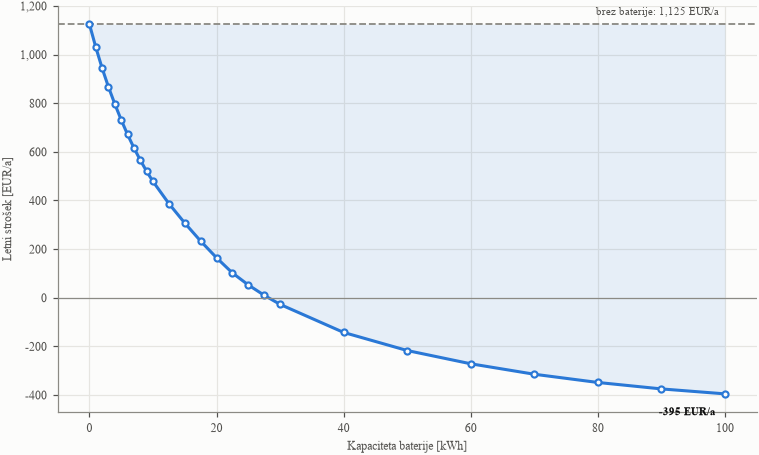

In [ ]:
### Annual electricity cost vs battery size
fig, ax = plt.subplots()
cap = df_sizing["Capacity_kWh"]

ax.axhline(cost_no_battery, color=MUTED, lw=1.2, ls="--")
ax.annotate(f"brez baterije: {cost_no_battery:,.0f} EUR/a",
            xy=(cap.max(), cost_no_battery), xytext=(-4, 6),
            textcoords="offset points", ha="right", color=INK_2, fontsize=9)
ax.fill_between(cap, df_sizing["Cost_EUR"], cost_no_battery,
                color=SERIES[0], alpha=0.10, lw=0)
ax.plot(cap, df_sizing["Cost_EUR"], color=SERIES[0], lw=2,
        marker="o", ms=4, mfc=SURFACE, mew=1.4)
ax.axhline(0, color=MUTED, lw=0.8)

ax.annotate(f"{df_sizing['Cost_EUR'].iloc[-1]:,.0f} EUR/a",
            xy=(cap.iloc[-1], df_sizing["Cost_EUR"].iloc[-1]), xytext=(-6, -14),
            textcoords="offset points", ha="right", color=INK, fontsize=9,
            fontweight="semibold")

finish(ax, title="Letni strošek elektrike ob popolnem predvidevanju pada z velikostjo baterije",
       xlabel="Kapaciteta baterije [kWh]", ylabel="Letni strošek [EUR/a]", yfmt=EUR)
pf.show(fig, "cost_vs_capacity")


findfont: Failed to find font weight semibold, now using 700.


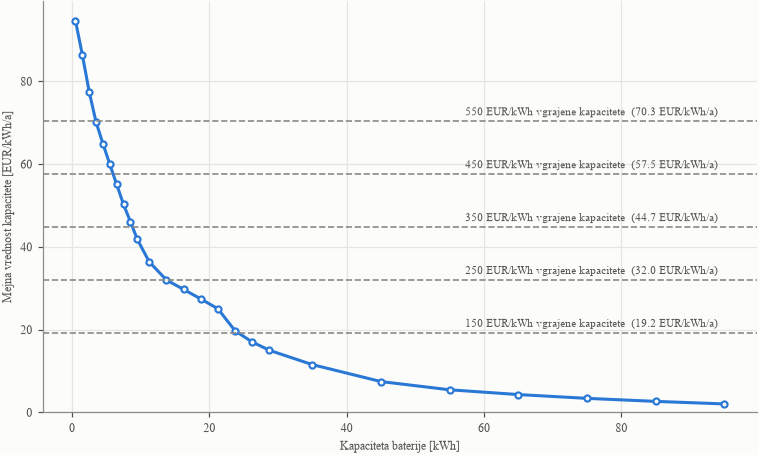

In [ ]:
### Marginal value of capacity vs what capacity costs
fig, ax = plt.subplots()
mid = (df_sizing["Capacity_kWh"] + df_sizing["Capacity_kWh"].shift()) / 2

ax.plot(mid, df_sizing["Marginal_EUR_per_kWh"], color=SERIES[0], lw=2,
        marker="o", ms=4, mfc=SURFACE, mew=1.4)

for capex in CAPEX_SCENARIOS_EUR_PER_KWH:
    # Capital recovery plus O&M: what owning that kWh costs for a year.
    level = capex * yearly_cost_factor
    ax.axhline(level, color=MUTED, lw=1.1, ls="--")
    ax.annotate(f"{capex:,.0f} EUR/kWh vgrajene kapacitete  ({level:,.1f} EUR/kWh/a)",
                xy=(mid.max(), level), xytext=(-4, 4), textcoords="offset points",
                ha="right", color=INK_2, fontsize=9)

ax.set_ylim(bottom=0)
finish(ax, title="Kje se naslednja kWh hrambe ne izplača več",
       xlabel="Kapaciteta baterije [kWh]", ylabel="Mejna vrednost kapacitete [EUR/kWh/a]", yfmt=EUR)
pf.show(fig, "marginal_value")


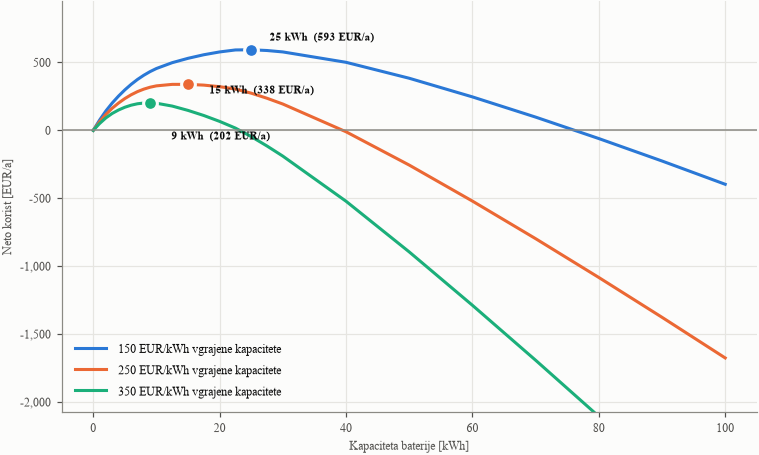

   150 EUR/kWh installed -> optimal  25.0 kWh, net   593.09 EUR/a
   250 EUR/kWh installed -> optimal  15.0 kWh, net   338.47 EUR/a
   350 EUR/kWh installed -> optimal   9.0 kWh, net   202.47 EUR/a


In [ ]:
### Net annual benefit
fig, ax = plt.subplots()

optima = {}
label_offsets = [(12, 6), (14, -6), (14, -24)]
for capex, colour, offset in zip(CAPEX_SCENARIOS_EUR_PER_KWH, SERIES, label_offsets):
    net = df_sizing[f"Net_{int(capex)}"]
    ax.plot(cap, net, color=colour, lw=2, label=f"{capex:,.0f} EUR/kWh vgrajene kapacitete")
    best = int(net.idxmax())
    optima[capex] = (float(df_sizing["Capacity_kWh"][best]), float(net[best]))
    ax.plot([optima[capex][0]], [optima[capex][1]], marker="o", ms=9,
            color=colour, mfc=colour, mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"{optima[capex][0]:g} kWh  ({optima[capex][1]:,.0f} EUR/a)",
                xy=optima[capex], xytext=offset, textcoords="offset points",
                color=INK, fontsize=9, fontweight="semibold")

ax.axhline(0, color=MUTED, lw=1.0)
best_net = max(v for _, v in optima.values())
ax.set_ylim(-max(300.0, 3.5 * best_net), max(60.0, 1.6 * best_net))
finish(ax, title="Neto letna korist = prihranek MILP − letni strošek baterije",
       xlabel="Kapaciteta baterije [kWh]", ylabel="Neto korist [EUR/a]", yfmt=EUR)
ax.legend(loc="lower left")
pf.show(fig, "net_annual_benefit", save_pdf=True)

for capex, (size, net) in optima.items():
    print(f"{capex:6.0f} EUR/kWh installed -> optimal {size:5.1f} kWh, "
          f"net {net:8.2f} EUR/a")


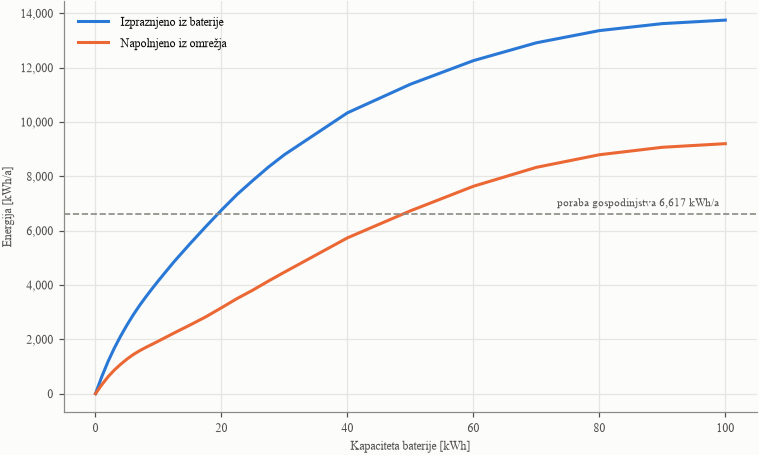

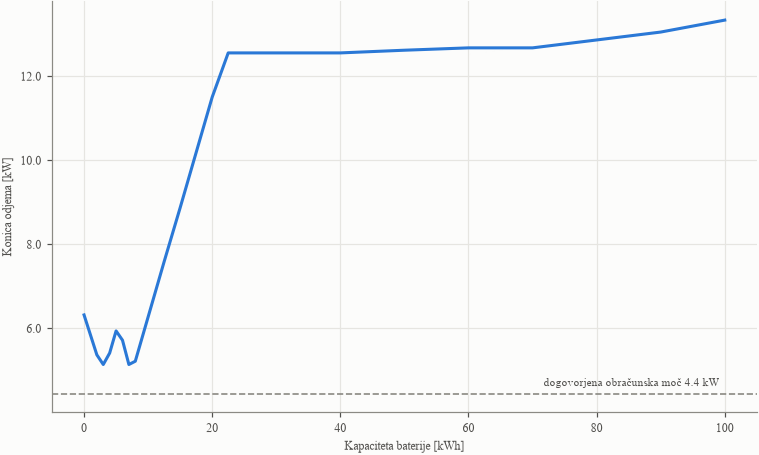

In [ ]:
### Diagnostics
fig, ax = plt.subplots()
ax.plot(cap, df_sizing["Discharged_kWh"], color=SERIES[0], lw=2, label="Izpraznjeno iz baterije")
ax.plot(cap, df_sizing["Grid_Charged_kWh"], color=SERIES[1], lw=2, label="Napolnjeno iz omrežja")
ax.axhline(annual_consumption_kwh, color=MUTED, lw=1.1, ls="--")
ax.annotate(f"poraba gospodinjstva {annual_consumption_kwh:,.0f} kWh/a",
            xy=(cap.max(), annual_consumption_kwh), xytext=(-4, 5),
            textcoords="offset points", ha="right", color=INK_2, fontsize=9)
finish(ax, title="Pretok energije skozi baterijo", xlabel="Kapaciteta baterije [kWh]",
       ylabel="Energija [kWh/a]", yfmt=PLAIN)
ax.legend(loc="upper left")
pf.show(fig, "energy_through_battery")

fig, ax = plt.subplots()
ax.plot(cap, df_sizing["Peak_Import_kW"], color=SERIES[0], lw=2)
contracted = float(list(build_env(0.0).contracted_power_kw.values())[0])
ax.axhline(contracted, color=MUTED, lw=1.1, ls="--")
ax.annotate(f"dogovorjena obračunska moč {contracted:,.1f} kW",
            xy=(cap.max(), contracted), xytext=(-4, 5), textcoords="offset points",
            ha="right", color=INK_2, fontsize=9)
finish(ax, title="Konica odjema iz omrežja", xlabel="Kapaciteta baterije [kWh]",
       ylabel="Konica odjema [kW]", yfmt=KW)
pf.show(fig, "peak_grid_import")


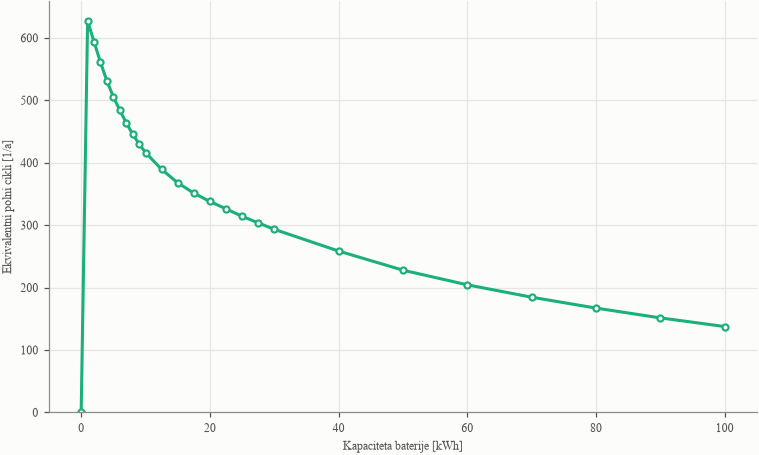

,Capacity_kWh,Equivalent_Full_Cycles
0,0.0,0.0
1,1.0,627.0
2,2.0,593.7
3,3.0,560.7
4,4.0,530.9
5,5.0,505.6
6,6.0,484.1
7,7.0,463.9
8,8.0,445.8
9,9.0,429.9


In [ ]:
### Equivalent full cycles vs battery size
fig, ax = plt.subplots()

ax.plot(cap, df_sizing["Equivalent_Full_Cycles"], color=SERIES[2], lw=2,
        marker="o", ms=4, mfc=SURFACE, mew=1.4)
ax.set_ylim(bottom=0)
finish(ax, title="Ekvivalentni polni cikli na leto", xlabel="Kapaciteta baterije [kWh]",
       ylabel="Ekvivalentni polni cikli [1/a]", yfmt=PLAIN)
pf.show(fig, "equivalent_full_cycles")

df_sizing[["Capacity_kWh", "Equivalent_Full_Cycles"]].round(1)


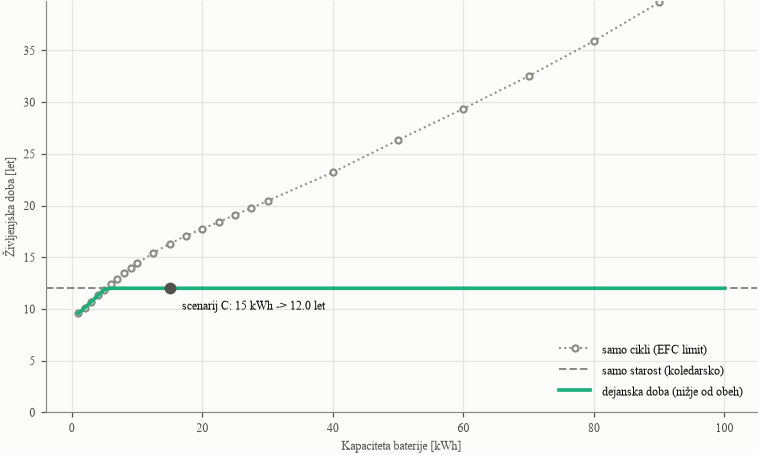

Nad 6.0 kWh cikli ne omejujejo več -- prevzame koledarska starost (12 let).


In [ ]:
### Aging: how the cycle limit's bite depends on battery size illustrative

cap_life = df_sizing.loc[df_sizing["Capacity_kWh"] > 0, "Capacity_kWh"].to_numpy()
efc_life = df_sizing.loc[df_sizing["Capacity_kWh"] > 0, "Equivalent_Full_Cycles"].to_numpy()
cycle_life_y = np.where(efc_life > 0, BATTERY_CYCLE_LIMIT_EFC / efc_life, np.inf)
service_life_y = np.minimum(cycle_life_y, BATTERY_LIFETIME_YEARS)

finite_cycle_life = cycle_life_y[np.isfinite(cycle_life_y)]
y_top = max(
    BATTERY_LIFETIME_YEARS,
    np.percentile(finite_cycle_life, 90) if finite_cycle_life.size else BATTERY_LIFETIME_YEARS,
) * 1.15

fig, ax = plt.subplots()
ax.plot(cap_life, cycle_life_y, color=MUTED, lw=1.3, ls=":", marker="o", ms=4,
        mfc=SURFACE, mew=1.4, label="samo cikli (EFC limit)")
ax.axhline(BATTERY_LIFETIME_YEARS, color=MUTED, lw=1.3, ls="--", label="samo starost (koledarsko)")
ax.plot(cap_life, service_life_y, color=SERIES[2], lw=2.4,
        label="dejanska doba (nižje od obeh)")

size_C_life = float(np.interp(size_C, cap_life, service_life_y))
ax.scatter([size_C], [size_C_life], color=INK_2, zorder=5, s=45)
ax.annotate(f"scenarij C: {size_C:g} kWh -> {size_C_life:.1f} let",
            xy=(size_C, size_C_life), xytext=(8, -14), textcoords="offset points")

ax.set_ylim(0, y_top)
finish(ax, title="Kako velikost baterije premakne konec življenjske dobe",
       xlabel="Kapaciteta baterije [kWh]", ylabel="Življenjska doba [let]", yfmt=YEARS)
ax.legend(loc="lower right")
pf.show(fig, "service_life")

crossover = cap_life[cycle_life_y >= BATTERY_LIFETIME_YEARS]
if len(crossover):
    print(f"Nad {crossover.min():.1f} kWh cikli ne omejujejo več -- prevzame koledarska "
          f"starost ({BATTERY_LIFETIME_YEARS:.0f} let).")
else:
    print(f"V celotnem prikazanem razponu velikosti cikli omejujejo pred koledarskim "
          f"staranjem ({BATTERY_LIFETIME_YEARS:.0f} let).")


## 7. Read-out

In [ ]:
best_capex = CAPEX_SCENARIOS_EUR_PER_KWH[-1]
lines = [
    f"Household {HOUSEHOLD_ID} ({DATASET_NAME}) — {annual_consumption_kwh:,.0f} kWh/a consumed, "
    f"{annual_generation_kwh:,.0f} kWh/a PV",
    f"Tariff: {anon.option_label(PAKET_ID)} ({PRICING_SCHEME}), "
    f"regime {PRICING_REFERENCE_YEAR}",
    f"Continuous MILP, {len(BATTERY_SIZES_KWH)} capacities from "
    f"{BATTERY_SIZES_KWH.min():.0f} to {BATTERY_SIZES_KWH.max():.0f} kWh",
    "",
    f"Cost without a battery          : {cost_no_battery:10,.2f} EUR/a",
    f"Cost at {BATTERY_SIZES_KWH.max():.0f} kWh                 : "
    f"{float(df_sizing['Cost_EUR'].iloc[-1]):10,.2f} EUR/a",
    f"Largest achievable saving       : {max_savings:10,.2f} EUR/a",
    f"95 % of it reached at           : {knee_kwh:10,.1f} kWh",
    "",
    "Optimal size by installed battery cost:",
]
for capex, (size, net) in optima.items():
    lines.append(f"   {capex:6,.0f} EUR/kWh -> {size:5.1f} kWh   (net {net:+8,.2f} EUR/a)")
lines += [
    "",
    "Break-even installed cost (EUR/kWh) — a battery of that size pays for itself below this:",
]
for _, r in df_sizing[df_sizing["Capacity_kWh"] > 0].iterrows():
    if r["Capacity_kWh"] in (5.0, 10.0, 20.0, 50.0, 100.0):
        lines.append(f"   {r['Capacity_kWh']:5.1f} kWh -> {r['Break_Even_Capex']:7,.0f} EUR/kWh"
                     f"   (simple payback at {REFERENCE_CAPEX:,.0f} EUR/kWh: "
                     f"{r['Payback_y']:5.1f} y)")

print("\n".join(lines))

Household 3-95546 (PorabaDoma_3-95546_2025) — 6,617 kWh/a consumed, 6,735 kWh/a PV
Tariff: Ponudnik 3 Samo Dinamični (si_samooskrba), regime 2026
Continuous MILP, 26 capacities from 0 to 100 kWh

Cost without a battery          :   1,125.04 EUR/a
Cost at 100 kWh                 :    -395.33 EUR/a
Largest achievable saving       :   1,520.37 EUR/a
95 % of it reached at           :       80.0 kWh

Optimal size by installed battery cost:
      150 EUR/kWh ->  25.0 kWh   (net  +593.09 EUR/a)
      250 EUR/kWh ->  15.0 kWh   (net  +338.47 EUR/a)
      350 EUR/kWh ->   9.0 kWh   (net  +202.47 EUR/a)

Break-even installed cost (EUR/kWh) — a battery of that size pays for itself below this:
     5.0 kWh ->     616 EUR/kWh   (simple payback at 350 EUR/kWh:   4.8 y)
    10.0 kWh ->     506 EUR/kWh   (simple payback at 350 EUR/kWh:   5.9 y)
    20.0 kWh ->     376 EUR/kWh   (simple payback at 350 EUR/kWh:   8.2 y)
    50.0 kWh ->     210 EUR/kWh   (simple payback at 350 EUR/kWh:  16.2 y)
   100.0 

### Caveats

* **Perfect foresight.** Every point is an upper bound; a real controller captures only part.
* **0.1 % MIP gap**, roughly 0.4 EUR on this bill against ~20 EUR between capacities.
* **Arbitrage through the grid.** Exports are credited regardless of origin, so where the
  throughput panel shows a large grid-charged share the savings are trading revenue.
* **`peak_reset_months=None`** ratchets one peak across the year; `PEAK_RESET_MONTHS = 1` is
  the monthly settlement the SI regulation actually uses.
* **One year, one household.**
* **No connection/fuse cap on grid power.** The MILP only bounds the battery's own
  charge/discharge, at `min(C_RATE * capacity_kwh, INVERTER_MAX_KW)` — up to 11.0 kW once a
  pack is 22 kWh or larger. Net grid import/export itself is never capped (no fuse or
  connection-power constraint on `Import_kWh`/`Export_kWh`), so a large battery's arbitrage
  can push the export peak above what the roof alone (or a real connection) would allow —
  which is exactly what happens here: peak export rises from the roof's own 7.3 kW without a
  battery to above 10 kW once the battery starts buying cheap grid power to resell.
* **Agreed power is endogenous to this run's own dispatch.** `agreed_power_from_dispatch=True`
  is the `HouseholdEnvironment` default and is not overridden here, so the "dogovorjena moč"
  that sets network capacity charges is rolled month to month from THIS solve's own
  with-battery import peaks (one month lag), not from the no-battery profile. A battery that
  shaves its monthly peak therefore lowers its own future agreed power and network bill too —
  which is the behaviour the "Changed how agreed power is calculated" fix added; before it,
  agreed power was read off the no-battery consumption and the battery could not touch it.
* **Speeding the sweep up.** CBC's `threads=` knob (now plumbed through `full_period_solver`)
  measured no speed-up at all on this machine — a 20 kWh solve took 451.9s with `threads=4`
  against 443.9s single-threaded (a `threads=8` run was started but abandoned once `threads=4`
  showed no gain), so the bundled Windows CBC binary is evidently not thread-parallel here (it
  may still help on Linux/Mac builds of CBC, which are more commonly compiled with the parallel
  B&B enabled). The sweep's real slack is at the OUTER level instead: every capacity is an
  independent solve, so running several capacities at once in separate OS processes
  (`concurrent.futures.ProcessPoolExecutor`, one single-threaded CBC per worker) would
  parallelize almost linearly on this 8-core / 16-thread machine — plausibly a ~6-8x wall-clock
  cut on the sweep. That needs a top-level, importable worker function rather than the
  notebook-local closures `build_env`/`solve_year` used here (Windows starts worker processes
  by re-importing, so they cannot see functions defined interactively in the kernel), which is
  why it is not wired up inside this notebook directly.